# L1 · Primer contacto — Sesión 1: **Recibir**
### Introducción a las Ciencias de la Computación · UNAL Manizales

El 16 de noviembre de 1974, el radiotelescopio de Arecibo, en Puerto Rico, mandó hacia el cúmulo de estrellas M13 un mensaje de **1 679 bits**. Sin idioma, sin instrucciones, sin un "léase así". Solo ceros y unos.

Hoy ustedes son los extraterrestres que lo reciben.

**Cómo se trabaja en este cuaderno**

- Las preguntas de **Momento 1** se responden **en papel, antes de tocar el computador**. Tómenle foto y súbanla al final del cuaderno. No hay predicción mala: hay predicción no escrita.
- Cada herramienta es una **función**, y cada función se escribe **primero su contrato** (qué recibe, qué devuelve, qué supone) y **después** su código.
- Debajo de cada función hay una celda de **pruebas** con `assert`. Si una prueba falla, la celda se queja con un `AssertionError`. Eso no es un regaño: es la máquina diciéndoles exactamente dónde mirar.
- Las celdas que dicen **CAJA** ya vienen hechas. Pueden abrirlas, pero no hace falta: basta con su contrato. Así usan todos los días `print()` o `range()`.
- Donde dice `# TU CÓDIGO AQUÍ`, escriben ustedes. Donde dice ✍️, responden en texto.

In [1]:
# Integrantes del equipo (nombre completo)
EQUIPO = ["Durley Avalo", "Maria Lucia Calderon Perdomo", "Juan Jose Vargas Valencia"]

## Momento 1 — Predecir *(en papel, 15 minutos)*

**P1.** Les llega una cadena de 1 679 ceros y unos, sin nada más. ¿Qué es lo primero que intentarían para encontrarle sentido? Escriban tres ideas, en orden.

**P2.** Si alguien quisiera mandar un **dibujo** con bits, ¿cómo lo haría? ¿Qué tendría que adivinar quien lo recibe?

**P3.** ¿De cuántas maneras se pueden acomodar 1 679 cuadritos en un rectángulo completo, sin que sobre ni falte ninguno? Sin computador: con lo que saben de divisores.

✍️ *Copien aquí sus respuestas cortas (la foto del papel va al final):*

- P1: Para intentar descifrar la cadena de unos y ceros, lo que intentaríamos sería: 
1. Tratar de hacer una matriz con ellos, buscando los divisores de ese número, siendo los "1" cuadros negros y los "0" cuadros blancos y probando combinaciones de matrices hasta encontrar alguna que parezca tener sentido por sus patrones.
2. Buscar traducir cada cadena de 5 caracteres a números en base 10 y asociarlos cada uno a una letra del abecedario, traducirlo y revisar si sale algún mensaje.
3. Traducir cadenas de caracteres de tamaños aleatorios a otro tipo de base y ver si sale algo coherente

- P2: Se podría tratar de hacer una matriz con ellos, buscando los divisores de ese número, siendo los "1" cuadros negros y los "0" cuadros blancos y probando combinaciones de matrices hasta encontrar alguna que parezca tener sentido por sus patrones y el que lo recibe tendría que adivinar el tamaño de la matriz a partir de sus divisores.

- P3: Los divisores de 1679 son 1, 23, 73 y 1679, así que hay 4 maneras de acomodarlo (contando cada orden como distinto): 1×1679, 23×73, 73×23 y 1679×1.

## 0. Traer el mensaje

La celda que sigue es una **caja**. Su contrato es una línea: `cargar_mensaje()` devuelve una cadena de 1 679 caracteres, cada uno `'0'` o `'1'`. Si ya tienen el archivo `datos/arecibo.txt`, lo lee de ahí; si no, lo descarga de la copia congelada del curso o de la fuente original.

También trae `huella(bits)`, que devuelve cuántos unos tiene el mensaje y su **SHA-256**: una "huella digital" de 64 caracteres. Si cambia un solo bit del mensaje, la huella cambia por completo. Es la misma idea con la que su banco sabe que nadie alteró una transferencia en el camino.

In [2]:
# ==========================================================================
#  CAJA: traer el mensaje de Arecibo.  No hace falta abrirla; sí entender su contrato.
#  cargar_mensaje() -> str   Devuelve los 1679 caracteres '0'/'1' del mensaje.
#  Busca, en este orden: (1) el archivo datos/arecibo.txt si ya lo tienen,
#  (2) la copia congelada del repositorio de laboratorios, (3) la fuente original (Wikipedia).
# ==========================================================================
import os, re, html, hashlib, urllib.request

REPO_RAW = "https://raw.githubusercontent.com/cmorregof/labs-calculo-2026-2/main"
LONGITUD = 1679

def _descargar(url):
    pedido = urllib.request.Request(url, headers={"User-Agent": "UNAL-IntroCC-L1/1.0"})
    with urllib.request.urlopen(pedido, timeout=30) as r:
        return r.read().decode("utf-8", errors="replace")

def _extraer_bits(texto):
    if re.search(r"<tr\b", texto, flags=re.I):
        filas = [re.sub(r"\s", "", html.unescape(re.sub(r"<[^>]+>", "", "<" + re.split(r"</tr>", t, flags=re.I)[0])))
                 for t in re.split(r"<tr\b", texto, flags=re.I)[1:]]
        actual = []
        for f in filas + ["x"]:
            if f and set(f) <= {"0", "1"}:
                actual.append(f)
            else:
                if len("".join(actual)) == LONGITUD:
                    return "".join(actual)
                actual = []
    texto = html.unescape(re.sub(r"<[^>]+>", "\n", texto))
    bloques, actual = [], []
    for renglon in texto.splitlines():
        limpio = re.sub(r"\s", "", renglon)
        if limpio == "":
            continue
        if set(limpio) <= {"0", "1"}:
            actual.append(limpio)
        else:
            if actual:
                bloques.append("".join(actual))
            actual = []
    if actual:
        bloques.append("".join(actual))
    for b in bloques:
        if len(b) == LONGITUD:
            return b
    return None

def cargar_mensaje():
    for local in ("datos/arecibo.txt", "../datos/arecibo.txt"):
        if os.path.exists(local):
            with open(local) as f:
                print("Mensaje leído de", local)
                return f.read().strip()
    intentos = [REPO_RAW + "/datos/arecibo.txt",
                "https://en.wikipedia.org/w/index.php?title=Arecibo_message&action=raw",
                 "https://en.wikipedia.org/wiki/Arecibo_message"]
    for url in intentos:
        try:
            bits = _extraer_bits(_descargar(url))
            if bits:
                os.makedirs("datos", exist_ok=True)
                with open("datos/arecibo.txt", "w") as f:
                    f.write(bits)
                print("Mensaje descargado de", url)
                return bits
        except Exception as e:
            print("No se pudo con", url, "->", e)
    raise RuntimeError("No pude traer el mensaje. Avísenle al monitor: hay una copia de respaldo.")

def huella(bits):
    """Devuelve (número de unos, SHA-256). Si cambia un solo bit, el SHA-256 cambia por completo."""
    return bits.count("1"), hashlib.sha256(bits.encode("ascii")).hexdigest()

In [3]:
bits = cargar_mensaje()
unos, sha = huella(bits)
print("Unos:", unos)
print("Huella SHA-256:", sha)
print("Comparen estas dos cifras con las del README de introduccion_cc en el repositorio de laboratorios.")

Mensaje leído de datos/arecibo.txt
Unos: 397
Huella SHA-256: 24babf56f872fc2c38c940b4a438811be454f04a041fe56b3c239662f261dd66
Comparen estas dos cifras con las del README de introduccion_cc en el repositorio de laboratorios.


## 1. Conocer el dato

Antes de calcular nada, se mira. Un dato que no se miró antes de usarlo es un dato en el que se confió sin razón. Contesten **con código**:

- ¿Cuántos caracteres tiene `bits`? (`len`)
- ¿Qué caracteres **distintos** aparecen? (`set`)
- ¿Cuántos unos y cuántos ceros hay? (`.count`)
- Miren los primeros 60 caracteres. ¿Ven algún patrón a simple vista?

In [4]:
n_caracteres = len(bits)
distintos = set(bits)
n_unos = bits.count("1")
n_ceros = bits.count("0")

print("caracteres:", n_caracteres)
print("distintos :", distintos)
print("unos/ceros:", n_unos, n_ceros)
print(bits[:60])

caracteres: 1679
distintos : {'0', '1'}
unos/ceros: 397 1282
000000101010100000000000010100000101000000010010001000100010


In [5]:
# Pruebas
assert n_caracteres == 1679, "¿Seguro que contaron bien? El mensaje tiene 1679 bits."
assert distintos == {"0", "1"}, "Debería haber solo ceros y unos."
assert n_unos + n_ceros == n_caracteres
print("✔ Conocen el dato.")

✔ Conocen el dato.


**Una ironía para pensar.** En el archivo, cada bit del mensaje está guardado como un **carácter**, y en el disco un carácter ocupa 8 bits. Corran la celda: ¿cuántos bits ocupa en su computador el mensaje de 1 679 bits? Representar algo siempre cuesta algo, y lo que cuesta depende de la convención que se eligió.

In [6]:
bits_en_disco = len(bits.encode("ascii")) * 8
print("El mensaje tiene", len(bits), "bits de información y ocupa", bits_en_disco, "bits en el disco.")

El mensaje tiene 1679 bits de información y ocupa 13432 bits en el disco.


✍️ *¿Cuál es la diferencia entre el carácter `'1'` y el bit 1? Dos líneas.*
El carácter "1" es un símbolo de texto representado en la computadora por un código estándar (como ASCII 49).

El bit 1 es la unidad mínima de información binaria que representa directamente el valor numérico uno o un estado lógico activo.

La ironía: Al guardar cada bit del mensaje como un carácter de texto, el archivo exige 8 veces más espacio. Un mensaje que solo contiene 1 679 bits de información real termina ocupando 13 432 bits en el disco, porque la convención elegida obliga a usar 8 bits enteros para representar cada "1" o "0".

## 2. La llave: `es_primo(n)`

En la clase 5 escribieron esto en PSeInt:

```
esPrimo <- (n >= 2);
d <- 2;
Mientras d * d <= n y esPrimo Hacer
    Si n mod d = 0 Entonces
        esPrimo <- Falso;
    FinSi
    d <- d + 1;
FinMientras
```

Tradúzcanlo a Python **como función**. Recuerden el diccionario: `mod` es `%`, `y` es `and`, `Falso` es `False`, y lo que va dentro del `while` lo dice la sangría. La función **devuelve** el resultado con `return`; no lo imprime.

In [7]:
def es_primo(n):
    """CONTRATO
    Recibe: un entero n.
    Devuelve: True si n es primo, False si no.
    Supone: n >= 0.
    """
    if n < 2:
        return False
    i = 2
    while i*i <= n:
        if n%i == 0:
            return False
        i = i+1
    return True

In [8]:
# Pruebas
assert es_primo(2) and es_primo(3) and es_primo(97) and es_primo(1000003)
assert not es_primo(0) and not es_primo(1) and not es_primo(91) and not es_primo(1000001)
print("✔ es_primo pasa las pruebas.")
print("¿1679 es primo?", es_primo(1679))

✔ es_primo pasa las pruebas.
¿1679 es primo? False


## 3. Las formas posibles: `rectangulos(n)`

Un rectángulo de `filas × columnas` cuadritos usa exactamente `n` cuadritos cuando `filas * columnas == n`. La función devuelve **todas** las parejas posibles, ordenadas por número de filas.

Ejemplo: `rectangulos(12)` debe devolver `[(1, 12), (2, 6), (3, 4), (4, 3), (6, 2), (12, 1)]`.

In [9]:
def rectangulos(n):
    """CONTRATO
    Recibe: un entero n >= 1.
    Devuelve: la lista de parejas (filas, columnas) con filas * columnas == n,
    ordenada de menor a mayor número de filas.
    """
    rectangulos = []
    for i in range(1, n+1):
        if n % i == 0:
            rectangulos.append((i, n // i))
    return rectangulos

In [10]:
# Pruebas
assert rectangulos(12) == [(1, 12), (2, 6), (3, 4), (4, 3), (6, 2), (12, 1)]
assert rectangulos(7) == [(1, 7), (7, 1)]
assert len(rectangulos(1680)) == 40
print("✔ rectangulos pasa las pruebas.")
print("Formas de acomodar 1679:", rectangulos(1679))
print("Formas de acomodar 1680:", len(rectangulos(1680)))

✔ rectangulos pasa las pruebas.
Formas de acomodar 1679: [(1, 1679), (23, 73), (73, 23), (1679, 1)]
Formas de acomodar 1680: 40


✍️ **La pregunta de fondo** (va al informe). ¿Por qué quien diseñó el mensaje eligió un número que es producto de **dos primos**? ¿Qué habría pasado si el mensaje tuviera 1 680 bits, que se pueden acomodar de 40 maneras?

Se eligió 1 679 porque, al ser producto de dos primos, deja solo dos opciones reales para armar la cuadrícula (23×73 o 73×23). Las otras dos opciones matemáticas (1×1679 y 1679×1) se descartan de inmediato porque forman una simple línea de bits que no sirve para un dibujo.

Si el mensaje tuviera 1 680 bits habría 40 formas posibles; el peligro de esta ambigüedad es que varios de esos rectángulos podrían generar ruido o patrones visuales engañosos, haciendo imposible para el receptor distinguir cuál es el mensaje verdadero.

**Para quien termine antes: mejorar el algoritmo.** Su `rectangulos` probablemente prueba todos los números de 1 a `n`. Con la idea de la clase 5 basta probar hasta $\sqrt{n}$: cada divisor `d` pequeño trae de regalo a su pareja `n // d`. Escriban `rectangulos_rapido(n)`, cuenten las vueltas de cada versión con `n = 1679` y con `n = 1 000 000`, y comprueben que las dos devuelven lo mismo.

In [11]:
def rectangulos_rapido(n):
    """
    CONTRATO
    Recibe: un entero n >= 1.
    Devuelve: la lista de parejas (filas, columnas) con filas * columnas == n,
    ordenada de menor a mayor número de filas.
    Optimización: itera solo hasta la raíz cuadrada de n.
    """
    rectangulos_lista = []
    vueltas = 0
    for i in range(1, int(n**0.5) + 1):
        vueltas += 1
        if n % i == 0:
            rectangulos_lista.append((i, n // i))
            if i != n // i:
                rectangulos_lista.append((n // i, i))
    print(f"Versión rápida | n={n:<10} | Vueltas: {vueltas}")
    return sorted(rectangulos_lista)

In [12]:
# Comprobación de rectangulos_rapido
assert rectangulos_rapido(1679) == rectangulos(1679)
assert rectangulos_rapido(1000000) == rectangulos(1000000)
print("✔ rectangulos_rapido devuelve exactamente lo mismo.")

Versión rápida | n=1679       | Vueltas: 40
Versión rápida | n=1000000    | Vueltas: 1000
✔ rectangulos_rapido devuelve exactamente lo mismo.


## 4. Ver: `dibujar(bits, columnas)`

Ahora sí: acomodar los bits en filas y mirarlos. Lo hacemos en dos funciones, porque una función que **devuelve** se puede probar, y una que solo **imprime**, no.

- `filas_de(bits, columnas)` devuelve la lista de renglones, cada uno una cadena de `columnas` caracteres. Ejemplo: `filas_de("101100", 3)` es `["101", "100"]`.
- `dibujar(bits, columnas)` usa `filas_de` e imprime cada renglón cambiando `"1"` por `"█"` y `"0"` por un espacio.

In [13]:
def filas_de(bits, columnas):
    """CONTRATO
    Recibe: una cadena de bits y un número de columnas que divide su longitud.
    Devuelve: la lista de renglones, cada uno de longitud 'columnas'.
    """
    renglones = []
    # El paso del range salta de 'columnas' en 'columnas' para no leer bit por bit, sino por bloques enteros.
    for i in range(0, len(bits), columnas):
        # bits[i:i+columnas] recorta un fragmento de la cadena original que corresponde exactamente a un renglón.
        renglon = bits[i:i+columnas]
        renglones.append(renglon)
    return renglones


def dibujar(bits, columnas):
    """CONTRATO
    Recibe: una cadena de bits y un número de columnas.
    Devuelve: nada. Imprime los renglones con '█' para 1 y ' ' para 0.
    """
    renglones = filas_de(bits, columnas)

    for renglon in renglones:
        renglon_dibujado = ""
        for bit in renglon:
            if bit == "1":
                renglon_dibujado += "█"
            else:
                renglon_dibujado += " "
        print(renglon_dibujado)

In [14]:
# Pruebas
assert filas_de("101100", 3) == ["101", "100"]
assert filas_de("101100", 2) == ["10", "11", "00"]
assert len(filas_de(bits, 23)) == 73
print("✔ filas_de pasa las pruebas.")

✔ filas_de pasa las pruebas.


Prueben las dos formas que encontraron. **Una de las dos es ruido; la otra no.** Este es el momento de dejarlo correr y esperar a ver si coincide con lo que pensaban.

In [15]:
dibujar(bits, 73)

      █ █ █ █            █ █     █ █       █  █   █   █   █  █ ██  █ █ █ 
█ █ █ █ █ █  █  █                                     ██                 
  ██ █                   ██ █                  █ █ █                  ███
██                                ██    ███   ██    ██   █             ██
  █    ██ █   ██   ██    ██ █ █████ █████ █████ █████                    
      █                 █                            █                 ██
████             █████                       ██    ██    ███   ██   █    
   █         █    ██ █    ██   ███  ██ █ █████ █████ █████ █████         
                 █      ██         █           ██               █     ██ 
         ██████     ██      █████          ██             █        █     
   █     █      ██       █       ██    ██      █          ██   █    ██   
            ██  ██             ██   █    ██         ██    ██      █      
 █      █        █     █       ██        █   █        ██        █   █    
     █       █     █       █       █  

In [16]:
dibujar(bits, 23)

      █ █ █ █          
  █ █     █ █       █  
█   █   █   █  █ ██  █ 
█ █ █ █ █ █ █ █  █  █  
                       
            ██         
          ██ █         
          ██ █         
         █ █ █         
         █████         
                       
██    ███   ██    ██   
█             ██  █    
██ █   ██   ██    ██ █ 
█████ █████ █████ █████
                       
   █                 █ 
                       
    █                 █
█████             █████
                       
██    ██    ███   ██   
█       █         █    
██ █    ██   ███  ██ █ 
█████ █████ █████ █████
                       
   █      ██         █ 
          ██           
    █     ██          █
█████     ██      █████
          ██           
  █        █        █  
   █      ██       █   
    ██    ██      █    
      ██   █    ██     
          ██  ██       
      ██   █    ██     
    ██    ██      █    
   █      █        █   
  █       ██        █  
 █        ██        █  
 █         █    

✍️ **Sobre las dos formas del dibujo:**

- **73 columnas:** Es **ruido**. Al organizar los 1 679 bits en 73 columnas y 23 filas, los puntos aparecen dispersos sin ninguna regularidad ni forma reconocible.
- **23 columnas:** Muestra **estructura**. Al usar 23 columnas y 73 filas, aparecen patrones repetidos, bloques simétricos y columnas alineadas en la parte superior que parecen números.

La caja que sigue dibuja lo mismo como imagen, con la cuadrícula numerada. Les va a servir para ubicar filas y columnas en el paso 5.

In [17]:
# CAJA: dibujo con cuadrícula numerada, para encontrar filas y columnas.
# dibujar_imagen(bits, columnas) -> None   Muestra los bits como imagen: 1 = negro, 0 = blanco.
import matplotlib.pyplot as plt

def dibujar_imagen(bits, columnas, alto=12):
    filas = len(bits) // columnas
    matriz = [[int(bits[f * columnas + c]) for c in range(columnas)] for f in range(filas)]
    fig, ax = plt.subplots(figsize=(alto * columnas / max(filas, 1) + 1, alto))
    ax.imshow(matriz, cmap="Greys", interpolation="nearest")
    ax.set_xticks(range(0, columnas, 5)); ax.set_yticks(range(0, filas, 5))
    ax.set_xticks([x - 0.5 for x in range(columnas + 1)], minor=True)
    ax.set_yticks([y - 0.5 for y in range(filas + 1)], minor=True)
    ax.grid(which="minor", color="#dddddd", linewidth=0.4)
    ax.set_xlabel("columna"); ax.set_ylabel("fila")
    ax.set_title(f"{filas} filas x {columnas} columnas")
    plt.show()

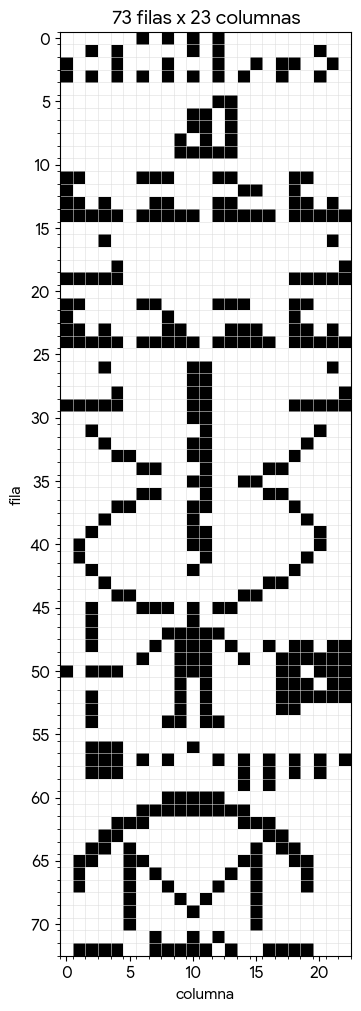

In [18]:
dibujar_imagen(bits, 23)

## 5. Leer: `leer_numero(columna)`

En la parte de arriba del dibujo hay números escritos en **binario**. Recordemos cómo se lee un número en base 2: cada posición vale el doble de la que tiene a la derecha.

$$1011_2 = 1\cdot 8 + 0\cdot 4 + 1\cdot 2 + 1\cdot 1 = 11$$

Hay una manera de leerlo con un ciclo y sin potencias, de izquierda a derecha: arrancar en 0 y, por cada bit, **duplicar lo que llevo y sumarle el bit**. Con `1011`: 0 → 1 → 2 → 5 → 11. Es un acumulador, como el de Gauss. Hagan la tabla de seguimiento en papel antes de escribirla.

In [19]:
def leer_numero(lista_bits):
    """CONTRATO
    Recibe: una lista de enteros 0 y 1; el primero es el más significativo.
    Devuelve: el entero que representan en base 2.
    """
    acumulador = 0
    for bit in lista_bits:
        # Por cada bit, duplicamos lo que llevamos y le sumamos el bit actual
        acumulador = acumulador * 2 + bit
    return acumulador

In [20]:
# Pruebas
assert leer_numero([1, 0, 1, 1]) == 11
assert leer_numero([0]) == 0 and leer_numero([1]) == 1
assert leer_numero([1, 0, 0, 0, 0, 0, 0, 0]) == 128
assert leer_numero([0, 0, 1, 1]) == 3
print("✔ leer_numero pasa las pruebas.")

✔ leer_numero pasa las pruebas.


Los números del mensaje están escritos **en vertical**, en columnas. Hace falta una herramienta para sacar un pedazo de columna de la cuadrícula.

In [21]:
def columna(bits, columnas, j, fila_desde, fila_hasta):
    """CONTRATO
    Recibe: los bits, el ancho de la cuadrícula, una columna j y un rango de filas.
    Devuelve: la lista de enteros (0/1) de la columna j, desde fila_desde hasta fila_hasta - 1,
              de arriba hacia abajo.
    """
    resultado = []
    # Recorremos el rango de filas indicado
    for fila in range(fila_desde, fila_hasta):
        # Calculamos la posición exacta del bit en la cadena plana original
        indice = fila * columnas + j
        # Convertimos el carácter ("0" o "1") a entero y lo agregamos a la lista
        resultado.append(int(bits[indice]))
    return resultado

In [22]:
# Pruebas (una cuadrícula de juguete de 3 x 4)
juguete = "1000" + "0101" + "1101"
assert columna(juguete, 4, 0, 0, 3) == [1, 0, 1]
assert columna(juguete, 4, 3, 1, 3) == [1, 1]
print("✔ columna pasa las pruebas.")

✔ columna pasa las pruebas.


Y una caja para mirar de cerca una región, con los números de fila y de columna al borde:

In [23]:
# CAJA: mirar de cerca una región.  recorte(bits, columnas, f0, f1, c0, c1) imprime
# las filas f0..f1-1 y las columnas c0..c1-1, con los números de fila y de columna al borde.
def recorte(bits, columnas, f0, f1, c0, c1):
    print("     " + "".join(str(c % 10) for c in range(c0, c1)))
    for f in range(f0, f1):
        fila = bits[f * columnas:(f + 1) * columnas]
        print(f"{f:3d}  " + "".join("█" if ch == "1" else "·" for ch in fila[c0:c1]))

In [24]:
recorte(bits, 23, 0, 12, 0, 23)    # las primeras 12 filas, todas las columnas

     01234567890123456789012
  0  ······█·█·█·█··········
  1  ··█·█·····█·█·······█··
  2  █···█···█···█··█·██··█·
  3  █·█·█·█·█·█·█·█··█··█··
  4  ·······················
  5  ············██·········
  6  ··········██·█·········
  7  ··········██·█·········
  8  ·········█·█·█·········
  9  ·········█████·········
 10  ·······················
 11  ██····███···██····██···


### Descifrar

1. **La primera sección.** Ubiquen, en las primeras filas, las columnas que forman números. Extráiganlas con `columna(...)` y léanlas con `leer_numero(...)`. Hay **una sola dirección** de lectura (de arriba abajo, o de abajo arriba con `lista[::-1]`) que hace que la sección diga algo que reconocen. Encuéntrenla probando las dos.
   - Ojo: puede haber bits que **no** son parte del número, sino marcas que dicen "aquí hay un número". ¿Hay una fila con un 1 debajo de cada número?
   - Algunos números pueden ocupar más de una columna. ¿Cuáles, y por qué?
2. **La segunda sección.** Un poco más abajo hay cinco números más. Léanlos igual y búsquenlos en la tabla periódica de la celda siguiente.

In [25]:
# Los primeros 20 elementos de la tabla periódica, por número atómico
TABLA_PERIODICA = {1: "H hidrógeno", 2: "He helio", 3: "Li litio", 4: "Be berilio", 5: "B boro",
                   6: "C carbono", 7: "N nitrógeno", 8: "O oxígeno", 9: "F flúor", 10: "Ne neón",
                   11: "Na sodio", 12: "Mg magnesio", 13: "Al aluminio", 14: "Si silicio",
                   15: "P fósforo", 16: "S azufre", 17: "Cl cloro", 18: "Ar argón",
                   19: "K potasio", 20: "Ca calcio"}

In [26]:
# Su exploración.

# --- Primera sección (filas 0 a 2) ---
print("Números de una sola columna (del 1 al 7) de arriba a abajo:")
for j in range(0, 13, 2):
    c_bits = columna(bits, 23, j, 0, 3)
    print(f"Columna {j}: {c_bits} -> Valor: {leer_numero(c_bits)}")

print("\nNúmeros de dos columnas (8, 9 y 10) de arriba a abajo:")
# Los números 8, 9 y 10 ocupan dos columnas; se leen combinando la columna derecha y la izquierda
for izq, der in ((14, 15), (17, 18), (20, 21)):
    bits_combinados = columna(bits, 23, der, 0, 3) + columna(bits, 23, izq, 0, 3)
    print(f"Columnas {der} y {izq}: {bits_combinados} -> Valor: {leer_numero(bits_combinados)}")

print("\nPrueba leyendo al revés (de abajo hacia arriba con [::-1]):")
al_reves = [leer_numero(columna(bits, 23, j, 0, 3)[::-1]) for j in range(0, 13, 2)]
print("Columnas 0 a 12 invertidas:", al_reves)

# --- Segunda sección (filas 5 a 9) ---
# Leemos horizontalmente las filas 5 a 9 (columnas 9 a 12).
print("\n--- Segunda sección (filas 5 a 9) ---")
for f in range(5, 10):
    # Extraemos los 4 bits (columnas 9, 10, 11 y 12) de la fila actual
    lista_bits = [int(bits[f * 23 + c]) for c in range(9, 13)]
    valor = leer_numero(lista_bits)
    print(f"Fila {f}: {valor}")

Números de una sola columna (del 1 al 7) de arriba a abajo:
Columna 0: [0, 0, 1] -> Valor: 1
Columna 2: [0, 1, 0] -> Valor: 2
Columna 4: [0, 1, 1] -> Valor: 3
Columna 6: [1, 0, 0] -> Valor: 4
Columna 8: [1, 0, 1] -> Valor: 5
Columna 10: [1, 1, 0] -> Valor: 6
Columna 12: [1, 1, 1] -> Valor: 7

Números de dos columnas (8, 9 y 10) de arriba a abajo:
Columnas 15 y 14: [0, 0, 1, 0, 0, 0] -> Valor: 8
Columnas 18 y 17: [0, 0, 1, 0, 0, 1] -> Valor: 9
Columnas 21 y 20: [0, 0, 1, 0, 1, 0] -> Valor: 10

Prueba leyendo al revés (de abajo hacia arriba con [::-1]):
Columnas 0 a 12 invertidas: [4, 2, 6, 1, 5, 3, 7]

--- Segunda sección (filas 5 a 9) ---
Fila 5: 1
Fila 6: 6
Fila 7: 6
Fila 8: 10
Fila 9: 15


✍️ **Lo que leyeron:**

- Primera sección (filas 0 a 2): los números 1 al 10. Dirección de lectura: de arriba a abajo, porque forma la secuencia natural de los números (1, 2, 3...) de manera ordenada; si se lee al revés, no tienen sentido.
- Segunda sección (filas 5 a 9): el código leyó horizontalmente los valores `1, 6, 6, 10, 15`. Por el contexto de la tabla periódica y las moléculas orgánicas, reconocemos que corresponden a los números atómicos `1, 6, 7, 8, 15`: H (hidrógeno), C (carbono), N (nitrógeno), O (oxígeno) y P (fósforo), que son los elementos del ADN.
- **Separación entre lectura del código y elementos reconocidos:** El recorrido horizontal del código en las filas 5 a 9 (columnas 9 a 12) produce `1, 6, 6, 10, 15`, mientras que los números atómicos reales del ADN que reconocemos por contexto son `1, 6, 7, 8, 15`.
- **Bits que difieren en las filas 7 y 8:** Al leer horizontalmente de izquierda a derecha, la fila 7 da `[0, 1, 1, 0]` (6), cuando para 7 (Nitrógeno) haría falta `[0, 1, 1, 1]`; difiere en un solo bit en la columna 12 (hay un 0 en lugar de 1). La fila 8 da `[1, 0, 1, 0]` (10), cuando para 8 (Oxígeno) haría falta `[1, 0, 0, 0]`; también difiere en un solo bit en la columna 11 (hay un 1 en lugar de 0).

## 6. Inventario

Con el dibujo y sus funciones, hagan la lista de lo que creen que dice cada parte del mensaje. **No hace falta descifrarlo todo**: hace falta separar lo que descifraron **con código** de lo que están adivinando **con los ojos**.

| Filas | Qué creemos que dice | ¿Lo leímos con código o lo adivinamos? | ¿Cómo lo comprobaríamos? |
|---|---|---|---|
| | | | |
| | | | |
| | | | |
| | | | |

## Momento 3 — Explicar *(media página por equipo)*

**La lista de convenciones.** El emisor supuso que el receptor ya sabía ciertas cosas. Escríbanlas todas las que encuentren, y para cada una decidan si un extraterrestre de verdad podría **deducirla** o tendría que **adivinarla**.

| Convención que supuso el emisor | ¿Se puede deducir o hay que adivinarla? | ¿Por qué? |
|---|---|---|
| Los bits forman un rectángulo | | |
| | | |
| | | |
| | | |

**Confrontación.** ¿Qué predijeron en P1, P2 y P3, qué encontraron y a qué atribuyen la diferencia?

**La frase obligatoria**, con sus palabras: *"Representar es..."*

✍️

## La IA como objeto de estudio *(para la bitácora individual)*

Denle a su asistente (Claude, o el que tengan) **la cadena de 1 679 bits sin decirle qué es**, y pídanle que la descifre. Guarden la respuesta completa en la bitácora.

¿La **descifró** (hizo cuentas que ustedes pueden verificar con sus funciones) o la **reconoció** (sabía de antemano qué era y recitó)? Propongan una prueba para distinguirlo. Pista: en la sesión 2 van a tener un mensaje que no está en ningún lugar de internet.

## 7. La revelación *(solo después del Momento 3)*

**No ejecuten esta parte hasta tener escritos el inventario y la lista de convenciones.** Lo que sigue es el mensaje pintado por secciones y ampliado, tal como lo describieron quienes lo diseñaron en 1974. Sirve para comparar, no para copiar: lo que vale es lo que ustedes descifraron con código antes de verlo.

La celda siguiente es una **CAJA**: `revelar(bits)` pinta el mensaje por secciones y `zoom(bits, seccion)` amplía una sección.

In [ ]:
# CAJA: la revelación.  revelar(bits) muestra el mensaje coloreado por secciones;
# zoom(bits, seccion) amplía una sección: "numeros", "elementos", "nucleotidos",
# "helice", "humano", "sistema_solar" o "telescopio".
import matplotlib.pyplot as plt
import numpy as np

_SECCIONES = {   # nombre: (fila_desde, fila_hasta, color, título)
    "numeros":       (0, 4,   "#555555", "Números del 1 al 10"),
    "elementos":     (4, 10,  "#7B3FB0", "Elementos: H, C, N, O, P"),
    "nucleotidos":   (10, 30, "#2E8B57", "Fórmulas de las piezas del ADN"),
    "helice":        (25, 46, "#2F6DB5", "Doble hélice del ADN"),
    "humano":        (45, 55, "#C9573C", "Ser humano, estatura y población"),
    "sistema_solar": (55, 60, "#D9A400", "Sistema solar"),
    "telescopio":    (60, 73, "#8B3A62", "Radiotelescopio de Arecibo"),
}

def _matriz(bits):
    return np.array([[int(bits[f * 23 + c]) for c in range(23)] for f in range(73)])

def _seccion_de(f, c):
    if f < 4: return "numeros"
    if f < 10: return "elementos"
    if f < 30 and not (f >= 25 and c in (10, 11)): return "nucleotidos"
    if f < 46: return "helice"
    if f < 55: return "humano"
    if f < 60: return "sistema_solar"
    return "telescopio"

def _rgb(h):
    return np.array([int(h[i:i + 2], 16) / 255 for i in (1, 3, 5)])

def _numero(columna_bits):
    v = 0
    for b in columna_bits:
        v = 2 * v + int(b)
    return v

def revelar(bits):
    M = _matriz(bits)
    img = np.ones((73, 23, 3))
    for f in range(73):
        for c in range(23):
            if M[f, c]:
                img[f, c] = _rgb(_SECCIONES[_seccion_de(f, c)][2])
    fig, ax = plt.subplots(figsize=(9, 12))
    ax.imshow(img, interpolation="nearest")
    ax.set_xticks([]); ax.set_yticks([])
    for nombre, (f0, f1, color, titulo) in _SECCIONES.items():
        y = {"helice": 37, "nucleotidos": 19.5, "humano": 50}.get(nombre, (f0 + f1 - 1) / 2)
        ax.annotate(titulo, xy=(23.5, y), fontsize=12, color=color, va="center", annotation_clip=False)
    ax.set_title("El mensaje de Arecibo (16 nov. 1974) · 1 679 bits = 73 × 23", loc="left")
    plt.subplots_adjust(right=0.55)
    plt.show()

def _rejilla(ax, f0, f1, c0=0, c1=23):
    ax.set_xticks(range(c1 - c0)); ax.set_xticklabels(range(c0, c1), fontsize=7)
    ax.set_yticks(range(f1 - f0)); ax.set_yticklabels(range(f0, f1), fontsize=7)
    ax.set_xticks(np.arange(-.5, c1 - c0, 1), minor=True); ax.set_yticks(np.arange(-.5, f1 - f0, 1), minor=True)
    ax.grid(which="minor", color="#cccccc", lw=0.5); ax.tick_params(which="minor", length=0)

def _pintar(ax, M, f0, f1, color, c0=0, c1=23, seccion=None):
    img = np.ones((f1 - f0, c1 - c0, 3))
    for f in range(f0, f1):
        for c in range(c0, c1):
            if M[f, c]:
                propio = seccion is None or _seccion_de(f, c) == seccion
                img[f - f0, c - c0] = _rgb(color) if propio else _rgb("#d0d0d0")
    ax.imshow(img, interpolation="nearest")
    _rejilla(ax, f0, f1, c0, c1)

def zoom(bits, seccion):
    M = _matriz(bits)
    f0, f1, color, titulo = _SECCIONES[seccion]
    if seccion == "nucleotidos":
        return _zoom_nucleotidos(M, color)
    fig, ax = plt.subplots(figsize=(10, max(2.5, 0.45 * (f1 - f0) + 1)))
    _pintar(ax, M, f0, f1, color, seccion=seccion)
    ax.set_title(titulo, loc="left", color=color, pad=40 if seccion in ("numeros", "elementos", "sistema_solar", "humano") else 8)
    ax.set_ylim(f1 - f0 - 0.5, -0.5)
    if seccion == "numeros":
        for j in (0, 2, 4, 6, 8, 10, 12):
            ax.text(j, -0.7, str(_numero(M[0:3, j])), ha="center", va="bottom", fontsize=11, fontweight="bold")
        for izq, der in ((14, 15), (17, 18), (20, 21)):
            ax.text(izq + 0.5, -0.7, str(_numero(list(M[0:3, der]) + list(M[0:3, izq]))), ha="center", va="bottom",
                    fontsize=11, fontweight="bold")
        ax.set_xlabel("Cada número se lee de arriba abajo; la fila 3 es la marca. El 8, el 9 y el 10 ocupan dos "
                      "columnas: la de la derecha lleva los bits altos.", fontsize=9)
    elif seccion == "elementos":
        nombres = {1: "H", 6: "C", 7: "N", 8: "O", 15: "P"}
        for j in range(9, 14):
            z = _numero(M[5:9, j])
            ax.text(j, -0.7, f"{z} {nombres.get(z, '?')}", ha="center", va="bottom", fontsize=9, fontweight="bold", rotation=90)
        ax.set_xlabel("Números atómicos 1, 6, 7, 8 y 15: hidrógeno, carbono, nitrógeno, oxígeno y fósforo, "
                      "los elementos del ADN.", fontsize=9)
    elif seccion == "helice":
        ax.set_xlabel("Las dos hebras retorcidas son la doble hélice. La barra del centro (columnas 10 y 11) es, "
                      "según sus diseñadores,\nel número de nucleótidos del genoma humano escrito en binario. "
                      "Termina justo en la cabeza del humano.", fontsize=9)
    elif seccion == "humano":
        ax.annotate("cabeza: un solo bit", xy=(10, 1), xytext=(13.5, 1.2), fontsize=9,
                    arrowprops=dict(arrowstyle="->", color="#333"))
        ax.text(2, -0.7, "estatura", ha="center", va="bottom", fontsize=9, fontweight="bold")
        ax.text(19.5, -0.7, "población", ha="center", va="bottom", fontsize=9, fontweight="bold")
        ax.set_xlabel("A la izquierda, una línea vertical con su número: la estatura. A la derecha, un número "
                      "en binario: la población de la Tierra en 1974.", fontsize=9)
    elif seccion == "sistema_solar":
        etiquetas = {3: "Sol", 6: "Mer", 8: "Ven", 10: "Tierra", 12: "Mar", 14: "Júp", 16: "Sat",
                     18: "Ura", 20: "Nep", 22: "Plu"}
        for c, t in etiquetas.items():
            ax.text(c, -0.7, t, ha="center", va="bottom", fontsize=8, rotation=60)
        ax.set_xlabel("\nEl Sol y nueve planetas (en 1974 Plutón contaba como planeta). La Tierra está levantada: "
                      "de ahí venimos.", fontsize=9)
    elif seccion == "telescopio":
        ax.set_xlabel("El radiotelescopio que mandó el mensaje, apuntando hacia abajo. La fila de abajo trae "
                      "su diámetro en binario.", fontsize=9)
    plt.tight_layout()
    plt.show()

def _zoom_nucleotidos(M, color):
    nombres = [["desoxirribosa", "adenina", "timina", "desoxirribosa"],
               ["fosfato", None, None, "fosfato"],
               ["desoxirribosa", "citosina", "guanina", "desoxirribosa"],
               ["fosfato", None, None, "fosfato"]]
    formulas = {"desoxirribosa": "C₅H₇O", "adenina": "C₅H₄N₅", "timina": "C₅H₅N₂O₂", "fosfato": "PO₄",
                "citosina": "C₄H₄N₃O", "guanina": "C₅H₄N₅O"}
    fig, ejes = plt.subplots(4, 4, figsize=(10, 10))
    for i, f0 in enumerate((11, 16, 21, 26)):
        for j, c0 in enumerate((0, 6, 12, 18)):
            a = ejes[i][j]
            if nombres[i][j] is None:
                a.axis("off"); continue
            caja = M[f0:f0 + 4, c0:c0 + 5]
            a.imshow(1 - caja, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
            a.set_xticks(range(5)); a.set_xticklabels(list("HCNOP")); a.xaxis.tick_top(); a.set_yticks([])
            a.set_xticks(np.arange(-.5, 5, 1), minor=True); a.set_yticks(np.arange(-.5, 4, 1), minor=True)
            a.grid(which="minor", color="#bbbbbb", lw=0.6); a.tick_params(which="minor", length=0)
            a.axhline(2.5, color=color, lw=1.5, ls="--")
            valores = [_numero(caja[0:3, c]) for c in range(5)]
            n = nombres[i][j]
            a.set_xlabel("  ".join(str(v) for v in valores) + f"\n{n}  {formulas[n]}", fontsize=9, color="#1d5c3a")
    fig.suptitle("Fórmulas de las piezas del ADN: cada caja es una molécula.\n"
                 "Cada columna, un número de 3 bits (la fila punteada es la marca); las columnas cuentan átomos de "
                 "H, C, N, O y P.", fontsize=10, x=0.02, ha="left")
    plt.tight_layout()
    plt.show()

In [ ]:
revelar(bits)

Ahora, sección por sección. Para cada una, comparen con su inventario: ¿qué leyeron bien con código?, ¿qué adivinaron bien con los ojos?, ¿qué se les pasó?

In [ ]:
zoom(bits, "numeros")

In [ ]:
zoom(bits, "elementos")

In [ ]:
zoom(bits, "nucleotidos")

In [ ]:
zoom(bits, "helice")

In [ ]:
zoom(bits, "humano")

In [ ]:
zoom(bits, "sistema_solar")

In [ ]:
zoom(bits, "telescopio")

✍️ **Después de la revelación** (tres preguntas, van al informe):

1. ¿Qué parte del mensaje habrían podido descifrar sin saber química? ¿Y sin saber que en 1974 Plutón contaba como planeta? Agreguen esas convenciones a su lista.
2. La cabeza del humano es **un solo bit**, y la barra del ADN termina justo en ella. ¿Es casualidad o es un mensaje? ¿Cómo lo sabrían?
3. Si ustedes hubieran diseñado el mensaje, ¿qué habrían cambiado para que fuera más fácil de leer? (Lo van a poder hacer en la sesión 2.)

## Foto de las predicciones

Suban la foto del papel de Momento 1 (en Colab: el ícono de carpeta a la izquierda → subir) y pongan aquí su nombre de archivo:

`foto_predicciones_sesion1.jpg`

---
### Antes de irse
1. **Ejecuten todo de arriba a abajo** (*Entorno de ejecución → Reiniciar y ejecutar todo*). Si algo falla, no está terminado.
2. **Guarden una copia en su repositorio `intro-cc`:** *Archivo → Guardar una copia en GitHub*. Cada integrante en el suyo.
3. La **bitácora de IA** es individual y va aparte (la plantilla es `bitacora_IA_L1.md`, en la carpeta `introduccion_cc` del repositorio de laboratorios).